In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import seaborn as sns


# Data Cleaning

In [2]:
DF = pd.read_excel("WDI_DATA.xlsx")
DF.head(7)

,Country Name,Country Code,Series Name,Series Code,1960 [YR1960],1961 [YR1961],1962 [YR1962],1963 [YR1963],1964 [YR1964],1965 [YR1965],...,2016 [YR2016],2017 [YR2017],2018 [YR2018],2019 [YR2019],2020 [YR2020],2021 [YR2021],2022 [YR2022],2023 [YR2023],2024 [YR2024],2025 [YR2025]
0,Afghanistan,AFG,"School enrollment, secondary (% gross)",SE.SEC.ENRR,NaN,NaN,NaN,NaN,NaN,NaN,...,53.435040,55.536430,57.357849,NaN,NaN,NaN,NaN,59.613602,NaN,NaN
1,Afghanistan,AFG,"Government expenditure on education, total (% ...",SE.XPD.TOTL.GD.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,4.543960,4.343190,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Afghanistan,AFG,"GDP per capita, PPP (constant 2021 internation...",NY.GDP.PCAP.PP.KD,NaN,NaN,NaN,NaN,NaN,NaN,...,2958.785399,2952.998916,2902.392113,2927.245144,2769.685745,2144.166570,1981.710168,1983.812620,1964.452289,NaN
3,Afghanistan,AFG,Urban population (% of total population),SP.URB.TOTL.IN.ZS,8.122551,8.389595,8.662664,8.942709,9.231134,9.529343,...,24.658835,24.835282,24.999165,25.143726,25.262210,25.347862,25.393925,25.473053,25.700735,25.940164
4,Afghanistan,AFG,GDP per capita (constant 2015 US$),NY.GDP.PCAP.KD,NaN,NaN,NaN,NaN,NaN,NaN,...,563.872337,562.769574,553.125152,557.861533,527.834554,408.625855,377.665627,378.066303,374.376696,NaN
5,Afghanistan,AFG,GDP per capita growth (annual %),NY.GDP.PCAP.KD.ZG,NaN,NaN,NaN,NaN,NaN,NaN,...,-0.300121,-0.195570,-1.713743,0.856295,-5.382515,-22.584482,-7.576669,0.106093,-0.975915,NaN
6,Albania,ALB,"School enrollment, secondary (% gross)",SE.SEC.ENRR,NaN,NaN,NaN,NaN,NaN,NaN,...,99.170755,97.574370,98.822388,99.015154,95.929447,97.665033,97.322471,96.136877,108.355392,NaN


### GDP

In [3]:
GDP_PPP = DF.loc[
    DF["Series Code"] ==  "NY.GDP.PCAP.PP.KD"	
]

GDP_PPP.head(10)

,Country Name,Country Code,Series Name,Series Code,1960 [YR1960],1961 [YR1961],1962 [YR1962],1963 [YR1963],1964 [YR1964],1965 [YR1965],...,2016 [YR2016],2017 [YR2017],2018 [YR2018],2019 [YR2019],2020 [YR2020],2021 [YR2021],2022 [YR2022],2023 [YR2023],2024 [YR2024],2025 [YR2025]
2,Afghanistan,AFG,"GDP per capita, PPP (constant 2021 internation...",NY.GDP.PCAP.PP.KD,NaN,NaN,NaN,NaN,NaN,NaN,...,2958.785399,2952.998916,2902.392113,2927.245144,2769.685745,2144.166570,1981.710168,1983.812620,1964.452289,NaN
8,Albania,ALB,"GDP per capita, PPP (constant 2021 internation...",NY.GDP.PCAP.PP.KD,NaN,NaN,NaN,NaN,NaN,NaN,...,14643.428561,15359.397458,16170.923433,16761.123018,16457.718974,18212.794718,19388.792728,20501.647073,21640.983577,22724.293819
14,Angola,AGO,"GDP per capita, PPP (constant 2021 internation...",NY.GDP.PCAP.PP.KD,NaN,NaN,NaN,NaN,NaN,NaN,...,10963.996789,10565.167648,10154.838923,9712.979449,8904.949006,8720.187687,8750.993630,8597.538788,8752.797471,8760.190820
20,Algeria,DZA,"GDP per capita, PPP (constant 2021 internation...",NY.GDP.PCAP.PP.KD,NaN,NaN,NaN,NaN,NaN,NaN,...,15511.685877,15427.664189,15343.426122,15199.198997,14194.155748,14496.865470,14782.200297,15159.324237,15501.919700,15882.713884
26,Argentina,ARG,"GDP per capita, PPP (constant 2021 internation...",NY.GDP.PCAP.PP.KD,NaN,NaN,NaN,NaN,NaN,NaN,...,27802.105720,28334.904185,27367.115094,26629.552942,23877.093140,26300.274261,27825.027349,27230.396850,26771.965765,27846.598460
32,Armenia,ARM,"GDP per capita, PPP (constant 2021 internation...",NY.GDP.PCAP.PP.KD,NaN,NaN,NaN,NaN,NaN,NaN,...,13192.994073,14243.874900,15037.045242,16215.360797,15052.935979,15921.705282,17886.178388,19402.751092,20078.784898,21153.478329
38,Bangladesh,BGD,"GDP per capita, PPP (constant 2021 internation...",NY.GDP.PCAP.PP.KD,NaN,NaN,NaN,NaN,NaN,NaN,...,5682.535535,6005.707188,6392.593340,6838.326116,7015.197928,7441.069140,7888.163891,8242.397990,8486.784957,8676.755762
44,Azerbaijan,AZE,"GDP per capita, PPP (constant 2021 internation...",NY.GDP.PCAP.PP.KD,NaN,NaN,NaN,NaN,NaN,NaN,...,19822.410594,19659.004856,19781.850906,20101.491875,19126.096851,20111.375695,21051.244229,21310.738692,22090.529803,22314.216896
50,Belarus,BLR,"GDP per capita, PPP (constant 2021 internation...",NY.GDP.PCAP.PP.KD,NaN,NaN,NaN,NaN,NaN,NaN,...,24846.830153,25503.980985,26363.462978,26798.820640,26731.495387,27611.180114,26537.508308,27782.438014,29135.946514,29666.211572
56,Belize,BLZ,"GDP per capita, PPP (constant 2021 internation...",NY.GDP.PCAP.PP.KD,NaN,NaN,NaN,NaN,NaN,NaN,...,12063.060037,11572.300793,11451.897941,11765.974866,10045.140416,11716.326782,12565.364583,12371.008655,12621.408196,12788.842371


In [4]:
Full_GDP = GDP_PPP.set_index("Country Name").iloc[:,3:]
Full_GDP


,1960 [YR1960],1961 [YR1961],1962 [YR1962],1963 [YR1963],1964 [YR1964],1965 [YR1965],1966 [YR1966],1967 [YR1967],1968 [YR1968],1969 [YR1969],...,2016 [YR2016],2017 [YR2017],2018 [YR2018],2019 [YR2019],2020 [YR2020],2021 [YR2021],2022 [YR2022],2023 [YR2023],2024 [YR2024],2025 [YR2025]
Country Name,,,,,,,,,,,,,,,,,,,,,
Afghanistan,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2958.785399,2952.998916,2902.392113,2927.245144,2769.685745,2144.166570,1981.710168,1983.812620,1964.452289,NaN
Albania,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,14643.428561,15359.397458,16170.923433,16761.123018,16457.718974,18212.794718,19388.792728,20501.647073,21640.983577,22724.293819
Angola,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,10963.996789,10565.167648,10154.838923,9712.979449,8904.949006,8720.187687,8750.993630,8597.538788,8752.797471,8760.190820
Algeria,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,15511.685877,15427.664189,15343.426122,15199.198997,14194.155748,14496.865470,14782.200297,15159.324237,15501.919700,15882.713884
Argentina,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,27802.105720,28334.904185,27367.115094,26629.552942,23877.093140,26300.274261,27825.027349,27230.396850,26771.965765,27846.598460
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Viet Nam,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,9743.188223,10290.548714,10936.893786,11628.613915,11851.396569,12048.901994,12979.763898,13534.799784,14396.421737,15457.349940
"Yemen, Rep.",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Zimbabwe,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,5070.424132,5234.406538,5415.493220,4993.865469,4527.739492,4827.109602,5036.783177,5218.045266,5211.897556,5529.233100


In [5]:
GDP = GDP_PPP.set_index("Country Name").iloc[:,33:]
GDP


,1990 [YR1990],1991 [YR1991],1992 [YR1992],1993 [YR1993],1994 [YR1994],1995 [YR1995],1996 [YR1996],1997 [YR1997],1998 [YR1998],1999 [YR1999],...,2016 [YR2016],2017 [YR2017],2018 [YR2018],2019 [YR2019],2020 [YR2020],2021 [YR2021],2022 [YR2022],2023 [YR2023],2024 [YR2024],2025 [YR2025]
Country Name,,,,,,,,,,,,,,,,,,,,,
Afghanistan,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2958.785399,2952.998916,2902.392113,2927.245144,2769.685745,2144.166570,1981.710168,1983.812620,1964.452289,NaN
Albania,5560.833935,4027.888807,3761.139808,4145.902505,4517.780079,5151.375962,5563.770078,4942.983500,5387.545887,6085.983397,...,14643.428561,15359.397458,16170.923433,16761.123018,16457.718974,18212.794718,19388.792728,20501.647073,21640.983577,22724.293819
Angola,8366.412716,8170.249394,7445.438367,5481.763868,5377.990350,5981.532576,6565.864794,6808.336281,6893.122653,6815.175306,...,10963.996789,10565.167648,10154.838923,9712.979449,8904.949006,8720.187687,8750.993630,8597.538788,8752.797471,8760.190820
Algeria,11728.545729,11314.864735,11241.415417,10743.706353,10414.034824,10588.443370,10808.878867,10725.967349,11094.887537,11292.037300,...,15511.685877,15427.664189,15343.426122,15199.198997,14194.155748,14496.865470,14782.200297,15159.324237,15501.919700,15882.713884
Argentina,17007.284432,18295.609200,19476.284061,20791.345148,21711.842788,20819.499948,21695.594952,23172.158340,23783.101719,22714.511130,...,27802.105720,28334.904185,27367.115094,26629.552942,23877.093140,26300.274261,27825.027349,27230.396850,26771.965765,27846.598460
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Viet Nam,2467.964601,2560.843835,2726.473737,2890.424317,3089.609337,3328.214860,3584.028983,3820.302495,3982.958060,4119.053672,...,9743.188223,10290.548714,10936.893786,11628.613915,11851.396569,12048.901994,12979.763898,13534.799784,14396.421737,15457.349940
"Yemen, Rep.",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Zimbabwe,6082.868798,6254.301825,5532.061365,5509.106975,6010.768452,5964.615215,6474.188225,6524.090916,6582.376930,6423.736692,...,5070.424132,5234.406538,5415.493220,4993.865469,4527.739492,4827.109602,5036.783177,5218.045266,5211.897556,5529.233100


In [6]:
logGDP = np.log(GDP)
logGDP

,1990 [YR1990],1991 [YR1991],1992 [YR1992],1993 [YR1993],1994 [YR1994],1995 [YR1995],1996 [YR1996],1997 [YR1997],1998 [YR1998],1999 [YR1999],...,2016 [YR2016],2017 [YR2017],2018 [YR2018],2019 [YR2019],2020 [YR2020],2021 [YR2021],2022 [YR2022],2023 [YR2023],2024 [YR2024],2025 [YR2025]
Country Name,,,,,,,,,,,,,,,,,,,,,
Afghanistan,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,7.992534,7.990577,7.973291,7.981817,7.926489,7.670506,7.591715,7.592776,7.582969,NaN
Albania,8.623503,8.300998,8.232477,8.329876,8.415776,8.547019,8.624031,8.505724,8.591845,8.713744,...,9.591747,9.639483,9.690970,9.726817,9.708550,9.809880,9.872450,9.928261,9.982344,10.031190
Angola,9.031980,9.008255,8.915357,8.609182,8.590070,8.696432,8.789640,8.825903,8.838279,8.826907,...,9.302372,9.265318,9.225706,9.181218,9.094362,9.073396,9.076923,9.059231,9.077129,9.077973
Algeria,9.369781,9.333873,9.327360,9.282075,9.250910,9.267518,9.288123,9.280423,9.314240,9.331853,...,9.649349,9.643918,9.638442,9.628998,9.560586,9.581688,9.601179,9.626371,9.648719,9.672987
Argentina,9.741397,9.814416,9.876953,9.942292,9.985613,9.943645,9.984865,10.050707,10.076731,10.030759,...,10.232867,10.251850,10.217097,10.189777,10.080675,10.177335,10.233691,10.212089,10.195111,10.234466
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Viet Nam,7.811149,7.848092,7.910764,7.969159,8.035800,8.110191,8.184243,8.248085,8.289780,8.323379,...,9.184324,9.238981,9.299897,9.361224,9.380201,9.396729,9.471147,9.513019,9.574735,9.645840
"Yemen, Rep.",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Zimbabwe,8.713232,8.741025,8.618316,8.614158,8.701308,8.693600,8.775579,8.783257,8.792151,8.767755,...,8.531180,8.563009,8.597019,8.515966,8.417978,8.482003,8.524523,8.559878,8.558699,8.617804


### Secondary School Enrollment

In [7]:
Sch_Edu_raw = DF.loc[
    DF["Series Code"] ==  "SE.SEC.ENRR"	
]

Sch_Edu_raw.head(10)

,Country Name,Country Code,Series Name,Series Code,1960 [YR1960],1961 [YR1961],1962 [YR1962],1963 [YR1963],1964 [YR1964],1965 [YR1965],...,2016 [YR2016],2017 [YR2017],2018 [YR2018],2019 [YR2019],2020 [YR2020],2021 [YR2021],2022 [YR2022],2023 [YR2023],2024 [YR2024],2025 [YR2025]
0,Afghanistan,AFG,"School enrollment, secondary (% gross)",SE.SEC.ENRR,NaN,NaN,NaN,NaN,NaN,NaN,...,53.435040,55.536430,57.357849,NaN,NaN,NaN,NaN,59.613602,NaN,NaN
6,Albania,ALB,"School enrollment, secondary (% gross)",SE.SEC.ENRR,NaN,NaN,NaN,NaN,NaN,NaN,...,99.170755,97.574370,98.822388,99.015154,95.929447,97.665033,97.322471,96.136877,108.355392,NaN
12,Angola,AGO,"School enrollment, secondary (% gross)",SE.SEC.ENRR,NaN,NaN,NaN,NaN,NaN,NaN,...,54.416799,NaN,NaN,NaN,NaN,53.135154,NaN,51.483905,NaN,NaN
18,Algeria,DZA,"School enrollment, secondary (% gross)",SE.SEC.ENRR,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,104.550270,101.264893,105.164132,NaN
24,Argentina,ARG,"School enrollment, secondary (% gross)",SE.SEC.ENRR,NaN,NaN,NaN,NaN,NaN,NaN,...,109.598328,110.377800,109.671242,110.460152,112.376732,115.735779,114.148117,105.574584,NaN,NaN
30,Armenia,ARM,"School enrollment, secondary (% gross)",SE.SEC.ENRR,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,83.024941,86.826063,88.508030,91.485374,91.710661,89.411103,90.945871,NaN
36,Bangladesh,BGD,"School enrollment, secondary (% gross)",SE.SEC.ENRR,NaN,NaN,NaN,NaN,NaN,NaN,...,64.166455,62.340864,65.271489,65.118541,66.432955,66.828232,67.038459,65.985660,64.299719,NaN
42,Azerbaijan,AZE,"School enrollment, secondary (% gross)",SE.SEC.ENRR,NaN,NaN,NaN,NaN,NaN,NaN,...,86.585694,89.262516,108.488781,107.863961,91.365514,91.410637,90.953036,92.740297,91.122804,NaN
48,Belarus,BLR,"School enrollment, secondary (% gross)",SE.SEC.ENRR,NaN,NaN,NaN,NaN,NaN,NaN,...,102.969006,102.480850,101.596011,100.438744,100.575710,100.420639,99.060203,97.426600,94.790270,NaN
54,Belize,BLZ,"School enrollment, secondary (% gross)",SE.SEC.ENRR,NaN,NaN,NaN,NaN,NaN,NaN,...,87.731373,86.323893,86.283356,87.452660,86.188660,88.821555,87.438167,83.619554,86.457158,NaN


In [8]:
Sch_Edu_Full = Sch_Edu_raw.set_index("Country Name").iloc[:,3:]
Sch_Edu_Full

,1960 [YR1960],1961 [YR1961],1962 [YR1962],1963 [YR1963],1964 [YR1964],1965 [YR1965],1966 [YR1966],1967 [YR1967],1968 [YR1968],1969 [YR1969],...,2016 [YR2016],2017 [YR2017],2018 [YR2018],2019 [YR2019],2020 [YR2020],2021 [YR2021],2022 [YR2022],2023 [YR2023],2024 [YR2024],2025 [YR2025]
Country Name,,,,,,,,,,,,,,,,,,,,,
Afghanistan,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,53.435040,55.536430,57.357849,NaN,NaN,NaN,NaN,59.613602,NaN,NaN
Albania,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,99.170755,97.574370,98.822388,99.015154,95.929447,97.665033,97.322471,96.136877,108.355392,NaN
Angola,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,54.416799,NaN,NaN,NaN,NaN,53.135154,NaN,51.483905,NaN,NaN
Algeria,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,104.550270,101.264893,105.164132,NaN
Argentina,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,109.598328,110.377800,109.671242,110.460152,112.376732,115.735779,114.148117,105.574584,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Viet Nam,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,90.158335,91.072520,92.837771,94.654622,93.192139,92.769021,93.412343,NaN,NaN,NaN
"Yemen, Rep.",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,43.690689,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Zimbabwe,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [9]:
Sch_Edu= Sch_Edu_raw.set_index("Country Name").iloc[:,33:]
Sch_Edu

,1990 [YR1990],1991 [YR1991],1992 [YR1992],1993 [YR1993],1994 [YR1994],1995 [YR1995],1996 [YR1996],1997 [YR1997],1998 [YR1998],1999 [YR1999],...,2016 [YR2016],2017 [YR2017],2018 [YR2018],2019 [YR2019],2020 [YR2020],2021 [YR2021],2022 [YR2022],2023 [YR2023],2024 [YR2024],2025 [YR2025]
Country Name,,,,,,,,,,,,,,,,,,,,,
Afghanistan,11.039550,17.183611,NaN,17.416910,23.468580,23.054520,NaN,NaN,NaN,NaN,...,53.435040,55.536430,57.357849,NaN,NaN,NaN,NaN,59.613602,NaN,NaN
Albania,90.841187,93.707687,80.463737,72.516083,70.497673,70.054268,68.990097,69.059052,70.327858,70.401100,...,99.170755,97.574370,98.822388,99.015154,95.929447,97.665033,97.322471,96.136877,108.355392,NaN
Angola,9.642070,10.173200,11.441050,NaN,NaN,NaN,NaN,NaN,11.897480,11.770890,...,54.416799,NaN,NaN,NaN,NaN,53.135154,NaN,51.483905,NaN,NaN
Algeria,60.615879,59.820271,60.101250,59.965199,60.480068,59.507660,58.931290,58.742439,NaN,64.745598,...,NaN,NaN,NaN,NaN,NaN,NaN,104.550270,101.264893,105.164132,NaN
Argentina,72.955566,74.131264,NaN,NaN,70.867752,NaN,78.492607,74.477280,80.652031,92.290466,...,109.598328,110.377800,109.671242,110.460152,112.376732,115.735779,114.148117,105.574584,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Viet Nam,35.117908,NaN,NaN,NaN,NaN,NaN,NaN,NaN,56.883980,NaN,...,90.158335,91.072520,92.837771,94.654622,93.192139,92.769021,93.412343,NaN,NaN,NaN
"Yemen, Rep.",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,36.079121,...,43.690689,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Zimbabwe,45.169281,46.478859,41.213879,38.712090,38.884071,40.178322,40.533009,41.581909,NaN,40.162830,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Urban Population

In [10]:
Urb_ppln_raw = DF.loc[
    DF["Series Code"] ==  "SP.URB.TOTL.IN.ZS"	
]
Urb_ppln_raw.head(10)

,Country Name,Country Code,Series Name,Series Code,1960 [YR1960],1961 [YR1961],1962 [YR1962],1963 [YR1963],1964 [YR1964],1965 [YR1965],...,2016 [YR2016],2017 [YR2017],2018 [YR2018],2019 [YR2019],2020 [YR2020],2021 [YR2021],2022 [YR2022],2023 [YR2023],2024 [YR2024],2025 [YR2025]
3,Afghanistan,AFG,Urban population (% of total population),SP.URB.TOTL.IN.ZS,8.122551,8.389595,8.662664,8.942709,9.231134,9.529343,...,24.658835,24.835282,24.999165,25.143726,25.262210,25.347862,25.393925,25.473053,25.700735,25.940164
9,Albania,ALB,Urban population (% of total population),SP.URB.TOTL.IN.ZS,30.842067,30.982751,31.073190,31.139806,31.190633,31.233706,...,55.573873,55.980276,56.377000,56.763907,57.140859,57.507719,57.864348,58.210609,58.546363,58.871474
15,Angola,AGO,Urban population (% of total population),SP.URB.TOTL.IN.ZS,10.387104,10.810545,11.207060,11.581720,11.945180,12.308095,...,64.299230,65.085053,65.873214,66.663782,67.456827,68.252416,69.050619,69.851503,70.655138,71.461592
21,Algeria,DZA,Urban population (% of total population),SP.URB.TOTL.IN.ZS,31.341294,32.882971,34.511760,36.055670,37.378389,38.343607,...,70.735378,71.322791,71.905250,72.482456,73.054113,73.619922,74.179586,74.732808,75.279291,75.818736
27,Argentina,ARG,Urban population (% of total population),SP.URB.TOTL.IN.ZS,71.723889,72.435474,73.172879,73.927374,74.687963,75.443651,...,91.585682,91.677603,91.767994,91.856784,91.943903,92.029278,92.112838,92.194513,92.274232,92.351922
33,Armenia,ARM,Urban population (% of total population),SP.URB.TOTL.IN.ZS,51.151337,52.481979,53.579094,54.617699,55.554516,56.057514,...,64.592875,64.712495,64.850283,65.004703,65.174217,65.357288,65.562446,65.695688,65.811367,65.928702
39,Bangladesh,BGD,Urban population (% of total population),SP.URB.TOTL.IN.ZS,5.112178,5.277111,5.465581,5.656050,5.854935,6.065048,...,29.875392,30.201580,30.517566,30.822840,31.116893,31.399216,31.673735,32.157847,32.678320,33.239585
45,Azerbaijan,AZE,Urban population (% of total population),SP.URB.TOTL.IN.ZS,48.096024,48.994537,49.009277,49.519924,49.528496,49.646301,...,55.757480,56.433189,57.184153,58.130819,58.293469,58.365997,58.438282,58.507535,58.573796,58.637102
51,Belarus,BLR,Urban population (% of total population),SP.URB.TOTL.IN.ZS,32.663029,33.895443,34.934948,35.947548,36.981735,38.023422,...,76.845871,77.020821,77.213272,77.455077,77.789039,78.131087,78.473279,78.814642,79.155102,79.494582
57,Belize,BLZ,Urban population (% of total population),SP.URB.TOTL.IN.ZS,53.885101,53.899827,53.931586,53.975710,54.027734,54.083192,...,43.676551,43.421109,43.164848,42.907762,42.649842,42.391081,42.137325,41.945944,41.753211,41.562144


In [11]:
Urb_ppln_Full = Urb_ppln_raw.set_index("Country Name").iloc[:,3:]
Urb_ppln_Full

,1960 [YR1960],1961 [YR1961],1962 [YR1962],1963 [YR1963],1964 [YR1964],1965 [YR1965],1966 [YR1966],1967 [YR1967],1968 [YR1968],1969 [YR1969],...,2016 [YR2016],2017 [YR2017],2018 [YR2018],2019 [YR2019],2020 [YR2020],2021 [YR2021],2022 [YR2022],2023 [YR2023],2024 [YR2024],2025 [YR2025]
Country Name,,,,,,,,,,,,,,,,,,,,,
Afghanistan,8.122551,8.389595,8.662664,8.942709,9.231134,9.529343,9.838740,10.160728,10.496712,10.848095,...,24.658835,24.835282,24.999165,25.143726,25.262210,25.347862,25.393925,25.473053,25.700735,25.940164
Albania,30.842067,30.982751,31.073190,31.139806,31.190633,31.233706,31.277061,31.328732,31.396753,31.490165,...,55.573873,55.980276,56.377000,56.763907,57.140859,57.507719,57.864348,58.210609,58.546363,58.871474
Angola,10.387104,10.810545,11.207060,11.581720,11.945180,12.308095,12.681118,13.074905,13.500110,13.967388,...,64.299230,65.085053,65.873214,66.663782,67.456827,68.252416,69.050619,69.851503,70.655138,71.461592
Algeria,31.341294,32.882971,34.511760,36.055670,37.378389,38.343607,38.838323,39.101684,39.311664,39.474071,...,70.735378,71.322791,71.905250,72.482456,73.054113,73.619922,74.179586,74.732808,75.279291,75.818736
Argentina,71.723889,72.435474,73.172879,73.927374,74.687963,75.443651,76.183442,76.896339,77.571347,78.197471,...,91.585682,91.677603,91.767994,91.856784,91.943903,92.029278,92.112838,92.194513,92.274232,92.351922
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Viet Nam,15.265452,15.722280,16.117120,16.506481,16.945107,17.536407,18.353159,19.287720,20.114211,20.626317,...,32.847619,33.362596,33.941023,34.623913,35.570668,36.654066,37.547852,38.129890,38.490070,38.829916
"Yemen, Rep.",3.400000,3.594849,3.799199,4.015082,4.244533,4.489583,4.752267,5.034617,5.338667,5.666450,...,32.951201,33.558691,34.210605,34.906756,35.702560,36.070495,36.322631,36.570798,36.807752,37.033666
Zimbabwe,12.467008,12.765667,13.077449,13.467384,13.964187,14.531922,15.139939,15.757591,16.354229,16.901508,...,34.079946,34.701495,35.408554,36.183764,37.009767,37.869206,38.705521,39.291937,39.893372,40.495129


In [12]:
Urb_ppln= Urb_ppln_Full.iloc[:,30:]
Urb_ppln

,1990 [YR1990],1991 [YR1991],1992 [YR1992],1993 [YR1993],1994 [YR1994],1995 [YR1995],1996 [YR1996],1997 [YR1997],1998 [YR1998],1999 [YR1999],...,2016 [YR2016],2017 [YR2017],2018 [YR2018],2019 [YR2019],2020 [YR2020],2021 [YR2021],2022 [YR2022],2023 [YR2023],2024 [YR2024],2025 [YR2025]
Country Name,,,,,,,,,,,,,,,,,,,,,
Afghanistan,17.264035,17.376660,17.488203,17.600467,17.715260,17.834385,17.959649,18.092857,18.235814,18.390327,...,24.658835,24.835282,24.999165,25.143726,25.262210,25.347862,25.393925,25.473053,25.700735,25.940164
Albania,35.897048,36.282412,36.718428,37.201625,37.728534,38.295684,38.899604,39.536825,40.203875,40.897284,...,55.573873,55.980276,56.377000,56.763907,57.140859,57.507719,57.864348,58.210609,58.546363,58.871474
Angola,37.878002,39.216271,40.520577,41.784095,43.000000,44.211003,45.455601,46.720650,47.993007,49.259527,...,64.299230,65.085053,65.873214,66.663782,67.456827,68.252416,69.050619,69.851503,70.655138,71.461592
Algeria,52.142128,52.927181,53.705230,54.477852,55.246622,56.013117,56.778914,57.545589,58.314700,59.084465,...,70.735378,71.322791,71.905250,72.482456,73.054113,73.619922,74.179586,74.732808,75.279291,75.818736
Argentina,86.919733,87.215028,87.481587,87.730771,87.964583,88.185368,88.395473,88.597245,88.793031,88.985176,...,91.585682,91.677603,91.767994,91.856784,91.943903,92.029278,92.112838,92.194513,92.274232,92.351922
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Viet Nam,19.173504,19.439680,19.825251,20.305768,20.856783,21.453846,22.072511,22.688328,23.276849,23.821228,...,32.847619,33.362596,33.941023,34.623913,35.570668,36.654066,37.547852,38.129890,38.490070,38.829916
"Yemen, Rep.",20.182053,20.982249,21.756953,22.492356,23.170080,23.798486,24.398954,24.980873,25.543258,26.085123,...,32.951201,33.558691,34.210605,34.906756,35.702560,36.070495,36.322631,36.570798,36.807752,37.033666
Zimbabwe,29.592041,30.155585,30.567425,30.875317,31.161894,31.429986,31.676908,31.899972,32.096492,32.263783,...,34.079946,34.701495,35.408554,36.183764,37.009767,37.869206,38.705521,39.291937,39.893372,40.495129


### Government Expenditure on Education

In [13]:
Gov_Exp_raw = DF.loc[
    DF["Series Code"] ==  "SE.XPD.TOTL.GD.ZS"	
]

Gov_Exp_raw.head(10)

,Country Name,Country Code,Series Name,Series Code,1960 [YR1960],1961 [YR1961],1962 [YR1962],1963 [YR1963],1964 [YR1964],1965 [YR1965],...,2016 [YR2016],2017 [YR2017],2018 [YR2018],2019 [YR2019],2020 [YR2020],2021 [YR2021],2022 [YR2022],2023 [YR2023],2024 [YR2024],2025 [YR2025]
1,Afghanistan,AFG,"Government expenditure on education, total (% ...",SE.XPD.TOTL.GD.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,4.543960,4.343190,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,Albania,ALB,"Government expenditure on education, total (% ...",SE.XPD.TOTL.GD.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,3.919970,3.546730,3.082014,3.870180,3.325050,3.005560,2.729780,3.091530,NaN,NaN
13,Angola,AGO,"Government expenditure on education, total (% ...",SE.XPD.TOTL.GD.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,2.754937,2.466879,2.183513,2.073064,2.667447,2.297197,2.385359,2.512737,NaN,NaN
19,Algeria,DZA,"Government expenditure on education, total (% ...",SE.XPD.TOTL.GD.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,6.502108,5.734824,5.812751,5.575366,6.193917,5.514033,4.749247,5.610157,8.977720,NaN
25,Argentina,ARG,"Government expenditure on education, total (% ...",SE.XPD.TOTL.GD.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,5.545490,5.454330,4.877740,4.771660,5.276900,4.653930,4.792630,5.003240,NaN,NaN
31,Armenia,ARM,"Government expenditure on education, total (% ...",SE.XPD.TOTL.GD.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,2.758120,2.707590,2.113312,2.159842,2.705560,2.767850,2.491900,2.438700,NaN,NaN
37,Bangladesh,BGD,"Government expenditure on education, total (% ...",SE.XPD.TOTL.GD.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,1.281840,2.113429,2.094775,1.130950,2.139744,2.170909,2.085387,2.162138,2.034385,NaN
43,Azerbaijan,AZE,"Government expenditure on education, total (% ...",SE.XPD.TOTL.GD.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,2.903410,2.473820,2.455430,3.176460,4.332050,3.702080,3.046890,3.660360,NaN,NaN
49,Belarus,BLR,"Government expenditure on education, total (% ...",SE.XPD.TOTL.GD.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,4.946550,4.795000,4.836570,4.979490,4.862640,4.606410,4.628230,4.909030,5.045940,NaN
55,Belize,BLZ,"Government expenditure on education, total (% ...",SE.XPD.TOTL.GD.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,5.726040,5.950720,6.127800,5.963780,5.213020,5.962990,4.604160,4.231430,4.622763,NaN


In [14]:
Gov_Exp_Full = Gov_Exp_raw.set_index("Country Name").iloc[:,3:]
Gov_Exp_Full


,1960 [YR1960],1961 [YR1961],1962 [YR1962],1963 [YR1963],1964 [YR1964],1965 [YR1965],1966 [YR1966],1967 [YR1967],1968 [YR1968],1969 [YR1969],...,2016 [YR2016],2017 [YR2017],2018 [YR2018],2019 [YR2019],2020 [YR2020],2021 [YR2021],2022 [YR2022],2023 [YR2023],2024 [YR2024],2025 [YR2025]
Country Name,,,,,,,,,,,,,,,,,,,,,
Afghanistan,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,4.543960,4.343190,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Albania,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,3.919970,3.546730,3.082014,3.870180,3.325050,3.005560,2.729780,3.091530,NaN,NaN
Angola,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2.754937,2.466879,2.183513,2.073064,2.667447,2.297197,2.385359,2.512737,NaN,NaN
Algeria,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,6.502108,5.734824,5.812751,5.575366,6.193917,5.514033,4.749247,5.610157,8.97772,NaN
Argentina,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,5.545490,5.454330,4.877740,4.771660,5.276900,4.653930,4.792630,5.003240,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Viet Nam,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,3.469070,3.418657,3.295370,3.084998,3.216529,2.945175,2.887387,NaN,NaN,NaN
"Yemen, Rep.",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Zimbabwe,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.384771,NaN,NaN


In [15]:
Gov_Exp = Gov_Exp_Full.iloc[:,30:]
Gov_Exp

,1990 [YR1990],1991 [YR1991],1992 [YR1992],1993 [YR1993],1994 [YR1994],1995 [YR1995],1996 [YR1996],1997 [YR1997],1998 [YR1998],1999 [YR1999],...,2016 [YR2016],2017 [YR2017],2018 [YR2018],2019 [YR2019],2020 [YR2020],2021 [YR2021],2022 [YR2022],2023 [YR2023],2024 [YR2024],2025 [YR2025]
Country Name,,,,,,,,,,,,,,,,,,,,,
Afghanistan,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,4.543960,4.343190,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Albania,NaN,NaN,NaN,NaN,3.44698,3.14191,3.05030,3.32768,3.46300,3.51435,...,3.919970,3.546730,3.082014,3.870180,3.325050,3.005560,2.729780,3.091530,NaN,NaN
Angola,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.56712,NaN,...,2.754937,2.466879,2.183513,2.073064,2.667447,2.297197,2.385359,2.512737,NaN,NaN
Algeria,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,6.502108,5.734824,5.812751,5.575366,6.193917,5.514033,4.749247,5.610157,8.97772,NaN
Argentina,1.06738,NaN,NaN,NaN,NaN,NaN,3.73198,NaN,4.03987,4.52168,...,5.545490,5.454330,4.877740,4.771660,5.276900,4.653930,4.792630,5.003240,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Viet Nam,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,3.469070,3.418657,3.295370,3.084998,3.216529,2.945175,2.887387,NaN,NaN,NaN
"Yemen, Rep.",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Zimbabwe,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.384771,NaN,NaN


### Final Variables

In [16]:
display(logGDP)
display(Sch_Edu)
display(Urb_ppln)
display(Gov_Exp)

,1990 [YR1990],1991 [YR1991],1992 [YR1992],1993 [YR1993],1994 [YR1994],1995 [YR1995],1996 [YR1996],1997 [YR1997],1998 [YR1998],1999 [YR1999],...,2016 [YR2016],2017 [YR2017],2018 [YR2018],2019 [YR2019],2020 [YR2020],2021 [YR2021],2022 [YR2022],2023 [YR2023],2024 [YR2024],2025 [YR2025]
Country Name,,,,,,,,,,,,,,,,,,,,,
Afghanistan,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,7.992534,7.990577,7.973291,7.981817,7.926489,7.670506,7.591715,7.592776,7.582969,NaN
Albania,8.623503,8.300998,8.232477,8.329876,8.415776,8.547019,8.624031,8.505724,8.591845,8.713744,...,9.591747,9.639483,9.690970,9.726817,9.708550,9.809880,9.872450,9.928261,9.982344,10.031190
Angola,9.031980,9.008255,8.915357,8.609182,8.590070,8.696432,8.789640,8.825903,8.838279,8.826907,...,9.302372,9.265318,9.225706,9.181218,9.094362,9.073396,9.076923,9.059231,9.077129,9.077973
Algeria,9.369781,9.333873,9.327360,9.282075,9.250910,9.267518,9.288123,9.280423,9.314240,9.331853,...,9.649349,9.643918,9.638442,9.628998,9.560586,9.581688,9.601179,9.626371,9.648719,9.672987
Argentina,9.741397,9.814416,9.876953,9.942292,9.985613,9.943645,9.984865,10.050707,10.076731,10.030759,...,10.232867,10.251850,10.217097,10.189777,10.080675,10.177335,10.233691,10.212089,10.195111,10.234466
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Viet Nam,7.811149,7.848092,7.910764,7.969159,8.035800,8.110191,8.184243,8.248085,8.289780,8.323379,...,9.184324,9.238981,9.299897,9.361224,9.380201,9.396729,9.471147,9.513019,9.574735,9.645840
"Yemen, Rep.",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Zimbabwe,8.713232,8.741025,8.618316,8.614158,8.701308,8.693600,8.775579,8.783257,8.792151,8.767755,...,8.531180,8.563009,8.597019,8.515966,8.417978,8.482003,8.524523,8.559878,8.558699,8.617804


,1990 [YR1990],1991 [YR1991],1992 [YR1992],1993 [YR1993],1994 [YR1994],1995 [YR1995],1996 [YR1996],1997 [YR1997],1998 [YR1998],1999 [YR1999],...,2016 [YR2016],2017 [YR2017],2018 [YR2018],2019 [YR2019],2020 [YR2020],2021 [YR2021],2022 [YR2022],2023 [YR2023],2024 [YR2024],2025 [YR2025]
Country Name,,,,,,,,,,,,,,,,,,,,,
Afghanistan,11.039550,17.183611,NaN,17.416910,23.468580,23.054520,NaN,NaN,NaN,NaN,...,53.435040,55.536430,57.357849,NaN,NaN,NaN,NaN,59.613602,NaN,NaN
Albania,90.841187,93.707687,80.463737,72.516083,70.497673,70.054268,68.990097,69.059052,70.327858,70.401100,...,99.170755,97.574370,98.822388,99.015154,95.929447,97.665033,97.322471,96.136877,108.355392,NaN
Angola,9.642070,10.173200,11.441050,NaN,NaN,NaN,NaN,NaN,11.897480,11.770890,...,54.416799,NaN,NaN,NaN,NaN,53.135154,NaN,51.483905,NaN,NaN
Algeria,60.615879,59.820271,60.101250,59.965199,60.480068,59.507660,58.931290,58.742439,NaN,64.745598,...,NaN,NaN,NaN,NaN,NaN,NaN,104.550270,101.264893,105.164132,NaN
Argentina,72.955566,74.131264,NaN,NaN,70.867752,NaN,78.492607,74.477280,80.652031,92.290466,...,109.598328,110.377800,109.671242,110.460152,112.376732,115.735779,114.148117,105.574584,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Viet Nam,35.117908,NaN,NaN,NaN,NaN,NaN,NaN,NaN,56.883980,NaN,...,90.158335,91.072520,92.837771,94.654622,93.192139,92.769021,93.412343,NaN,NaN,NaN
"Yemen, Rep.",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,36.079121,...,43.690689,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Zimbabwe,45.169281,46.478859,41.213879,38.712090,38.884071,40.178322,40.533009,41.581909,NaN,40.162830,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,1990 [YR1990],1991 [YR1991],1992 [YR1992],1993 [YR1993],1994 [YR1994],1995 [YR1995],1996 [YR1996],1997 [YR1997],1998 [YR1998],1999 [YR1999],...,2016 [YR2016],2017 [YR2017],2018 [YR2018],2019 [YR2019],2020 [YR2020],2021 [YR2021],2022 [YR2022],2023 [YR2023],2024 [YR2024],2025 [YR2025]
Country Name,,,,,,,,,,,,,,,,,,,,,
Afghanistan,17.264035,17.376660,17.488203,17.600467,17.715260,17.834385,17.959649,18.092857,18.235814,18.390327,...,24.658835,24.835282,24.999165,25.143726,25.262210,25.347862,25.393925,25.473053,25.700735,25.940164
Albania,35.897048,36.282412,36.718428,37.201625,37.728534,38.295684,38.899604,39.536825,40.203875,40.897284,...,55.573873,55.980276,56.377000,56.763907,57.140859,57.507719,57.864348,58.210609,58.546363,58.871474
Angola,37.878002,39.216271,40.520577,41.784095,43.000000,44.211003,45.455601,46.720650,47.993007,49.259527,...,64.299230,65.085053,65.873214,66.663782,67.456827,68.252416,69.050619,69.851503,70.655138,71.461592
Algeria,52.142128,52.927181,53.705230,54.477852,55.246622,56.013117,56.778914,57.545589,58.314700,59.084465,...,70.735378,71.322791,71.905250,72.482456,73.054113,73.619922,74.179586,74.732808,75.279291,75.818736
Argentina,86.919733,87.215028,87.481587,87.730771,87.964583,88.185368,88.395473,88.597245,88.793031,88.985176,...,91.585682,91.677603,91.767994,91.856784,91.943903,92.029278,92.112838,92.194513,92.274232,92.351922
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Viet Nam,19.173504,19.439680,19.825251,20.305768,20.856783,21.453846,22.072511,22.688328,23.276849,23.821228,...,32.847619,33.362596,33.941023,34.623913,35.570668,36.654066,37.547852,38.129890,38.490070,38.829916
"Yemen, Rep.",20.182053,20.982249,21.756953,22.492356,23.170080,23.798486,24.398954,24.980873,25.543258,26.085123,...,32.951201,33.558691,34.210605,34.906756,35.702560,36.070495,36.322631,36.570798,36.807752,37.033666
Zimbabwe,29.592041,30.155585,30.567425,30.875317,31.161894,31.429986,31.676908,31.899972,32.096492,32.263783,...,34.079946,34.701495,35.408554,36.183764,37.009767,37.869206,38.705521,39.291937,39.893372,40.495129


,1990 [YR1990],1991 [YR1991],1992 [YR1992],1993 [YR1993],1994 [YR1994],1995 [YR1995],1996 [YR1996],1997 [YR1997],1998 [YR1998],1999 [YR1999],...,2016 [YR2016],2017 [YR2017],2018 [YR2018],2019 [YR2019],2020 [YR2020],2021 [YR2021],2022 [YR2022],2023 [YR2023],2024 [YR2024],2025 [YR2025]
Country Name,,,,,,,,,,,,,,,,,,,,,
Afghanistan,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,4.543960,4.343190,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Albania,NaN,NaN,NaN,NaN,3.44698,3.14191,3.05030,3.32768,3.46300,3.51435,...,3.919970,3.546730,3.082014,3.870180,3.325050,3.005560,2.729780,3.091530,NaN,NaN
Angola,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.56712,NaN,...,2.754937,2.466879,2.183513,2.073064,2.667447,2.297197,2.385359,2.512737,NaN,NaN
Algeria,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,6.502108,5.734824,5.812751,5.575366,6.193917,5.514033,4.749247,5.610157,8.97772,NaN
Argentina,1.06738,NaN,NaN,NaN,NaN,NaN,3.73198,NaN,4.03987,4.52168,...,5.545490,5.454330,4.877740,4.771660,5.276900,4.653930,4.792630,5.003240,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Viet Nam,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,3.469070,3.418657,3.295370,3.084998,3.216529,2.945175,2.887387,NaN,NaN,NaN
"Yemen, Rep.",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Zimbabwe,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.384771,NaN,NaN


## Treating Missing Values

### Interpolation of One year gaps

In [17]:

# Preserve original data
Gov_Exp_original = Gov_Exp.copy()

# Retain 1990–2025
year_cols = [
    c for c in Gov_Exp.columns
    if 1990 <= int(str(c)[:4]) <= 2025
]

Gov_Exp_clean = Gov_Exp[year_cols].apply(
    pd.to_numeric, errors="coerce"
)

# Identify isolated missing observations
single_gap = (
    Gov_Exp_clean.isna()
    & Gov_Exp_clean.shift(axis=1).notna()
    & Gov_Exp_clean.shift(-1, axis=1).notna()
)

# Calculate linear interpolation
interpolated_values = (
    Gov_Exp_clean.shift(axis=1)
    + Gov_Exp_clean.shift(-1, axis=1)
) / 2

# Fill ONLY isolated one-year gaps
Gov_Exp_interp = Gov_Exp_clean.mask(
    single_gap,
    interpolated_values
)

# Check results
print("Original missing:", Gov_Exp_clean.isna().sum().sum())

print("Values interpolated:", single_gap.sum().sum())

print("Missing after interpolation:",
      Gov_Exp_interp.isna().sum().sum())


Original missing: 2275
Values interpolated: 120
Missing after interpolation: 2155


In [18]:
Sch_Edu_clean = Sch_Edu[year_cols].apply(
    pd.to_numeric, errors="coerce"
)

enrolment_gap = (
    Sch_Edu_clean.isna()
    & Sch_Edu_clean.shift(axis=1).notna()
    & Sch_Edu_clean.shift(-1, axis=1).notna()
)

Sch_Edu_interp = Sch_Edu_clean.mask(
    enrolment_gap,
    (
        Sch_Edu_clean.shift(axis=1)
        + Sch_Edu_clean.shift(-1, axis=1)
    ) / 2
)

print("Original missing:", Sch_Edu_clean.isna().sum().sum())

print("Values interpolated:", enrolment_gap.sum().sum())

print("Missing after interpolation:",
      Sch_Edu_interp.isna().sum().sum())

Original missing: 1941
Values interpolated: 140
Missing after interpolation: 1801


### Countries with missing values

In [19]:
# Use the interpolated spending series
coverage = pd.DataFrame({
    "Enrolment": Sch_Edu_interp.notna().sum(axis=1),
    "Education Spending": Gov_Exp_interp.notna().sum(axis=1),
    "GDP": logGDP.notna().sum(axis=1),
    "Urban": Urb_ppln.notna().sum(axis=1)
})

coverage["Complete Years"] = (
    Sch_Edu_interp.notna()
    & Gov_Exp_interp.notna()
    & logGDP.notna()
    & Urb_ppln.notna()
).sum(axis=1)

coverage = coverage.sort_values(
    "Complete Years", ascending=False
)

display(coverage)

,Enrolment,Education Spending,GDP,Urban,Complete Years
Country Name,,,,,
Malaysia,35,32,36,36,32
Thailand,34,33,36,36,31
"Iran, Islamic Rep.",32,32,36,36,30
Peru,35,29,36,36,29
Argentina,32,29,36,36,29
...,...,...,...,...,...
"Micronesia, Fed. Sts.",2,11,36,36,0
Montenegro,19,0,29,36,0
South Sudan,3,7,0,36,0


In [20]:

# A year is complete only when all four variables are observed
complete = (
    Sch_Edu_interp.notna()
    & Gov_Exp_interp.notna()
    & logGDP[year_cols].notna()
    & Urb_ppln[year_cols].notna()
)

def longest_run(row):
    longest = current = 0

    for observed in row:
        if observed:
            current += 1
            longest = max(longest, current)
        else:
            current = 0

    return longest

coverage["Longest Consecutive Run"] = (
    complete.apply(longest_run, axis=1)
)

coverage = coverage.sort_values(
    ["Longest Consecutive Run", "Complete Years"],
    ascending=False
)

display(coverage)


,Enrolment,Education Spending,GDP,Urban,Complete Years,Longest Consecutive Run
Country Name,,,,,,
Malaysia,35,32,36,36,32,32
Peru,35,29,36,36,29,29
Argentina,32,29,36,36,29,28
Bangladesh,28,32,36,36,28,27
St. Lucia,32,28,36,36,27,27
...,...,...,...,...,...,...
"Micronesia, Fed. Sts.",2,11,36,36,0,0
Montenegro,19,0,29,36,0,0
South Sudan,3,7,0,36,0,0


In [21]:

def longest_run_period(row):
    best_start = None
    best_end = None
    best_length = 0

    current_start = None
    current_length = 0

    for year, observed in row.items():
        if observed:
            if current_length == 0:
                current_start = year

            current_length += 1

            if current_length > best_length:
                best_length = current_length
                best_start = current_start
                best_end = year
        else:
            current_length = 0
            current_start = None

    return pd.Series({
        "Run Start": best_start,
        "Run End": best_end,
        "Run Length": best_length
    })

run_periods = complete.apply(
    longest_run_period, axis=1
)

coverage = coverage.join(run_periods.drop(
    columns="Run Length"
))

display(
    coverage.sort_values(
        "Longest Consecutive Run",
        ascending=False
    )
)


,Enrolment,Education Spending,GDP,Urban,Complete Years,Longest Consecutive Run,Run Start,Run End
Country Name,,,,,,,,
Malaysia,35,32,36,36,32,32,1992 [YR1992],2023 [YR2023]
Peru,35,29,36,36,29,29,1996 [YR1996],2024 [YR2024]
Argentina,32,29,36,36,29,28,1996 [YR1996],2023 [YR2023]
Bangladesh,28,32,36,36,28,27,1998 [YR1998],2024 [YR2024]
St. Lucia,32,28,36,36,27,27,1998 [YR1998],2024 [YR2024]
...,...,...,...,...,...,...,...,...
"Micronesia, Fed. Sts.",2,11,36,36,0,0,NaN,NaN
Montenegro,19,0,29,36,0,0,NaN,NaN
South Sudan,3,7,0,36,0,0,NaN,NaN


In [22]:

# Convert year labels into integer years
complete_years = complete.copy()

complete_years.columns = [
    int(str(c)[:4]) for c in complete_years.columns
]

# Test common windows of different lengths
results = []

for window in [10, 12, 15, 18, 20, 22, 25]:

    for start in range(1990, 2026 - window + 1):

        end = start + window - 1

        period = complete_years.loc[
            :, start:end
        ]

        # Countries with complete observations
        # throughout the selected window
        countries = period.all(axis=1).sum()

        results.append({
            "Start Year": start,
            "End Year": end,
            "Window": window,
            "Countries": countries
        })

window_results = pd.DataFrame(results)

# Show the best windows for each duration
best_windows = (
    window_results
    .sort_values(
        ["Window", "Countries"],
        ascending=[True, False]
    )
    .groupby("Window")
    .head(5)
    .sort_values(
        ["Window", "Countries"],
        ascending=[False, False]
    )
)

display(best_windows)


,Start Year,End Year,Window,Countries
134,1999,2023,25,10
133,1998,2022,25,7
135,2000,2024,25,6
131,1996,2020,25,3
132,1997,2021,25,3
121,2001,2022,22,15
120,2000,2021,22,14
122,2002,2023,22,14
119,1999,2020,22,12
118,1998,2019,22,7


In [23]:
selected_period = complete_years.loc[:, 2011:2020]

selected_countries = selected_period.index[
    selected_period.all(axis=1)
]

print("Countries retained:", len(selected_countries))
print(selected_countries.tolist())

Countries retained: 43
['Albania', 'Argentina', 'Bangladesh', 'Azerbaijan', 'Belarus', 'Belize', 'Bhutan', 'Bolivia', 'Burkina Faso', 'Burundi', 'Cabo Verde', 'Chad', 'Colombia', 'Dominican Republic', 'Ecuador', 'El Salvador', 'Fiji', 'Ghana', 'Guatemala', 'Indonesia', 'Kazakhstan', 'Jamaica', 'India', 'Kyrgyz Republic', 'Lao PDR', 'Maldives', 'Mauritius', 'Madagascar', 'Malaysia', 'Mexico', 'Moldova', 'Nepal', 'Peru', 'Pakistan', 'Namibia', 'Rwanda', 'South Africa', 'St. Lucia', 'Sierra Leone', 'Timor-Leste', 'Turkiye', 'Ukraine', 'Thailand']


In [25]:
# Provisional balanced sample: 2011–2020
final_years = [
    c for c in year_cols
    if 2011 <= int(str(c)[:4]) <= 2020
]

Sch_Edu_final = Sch_Edu_interp.loc[
    selected_countries, final_years
]

Gov_Exp_final = Gov_Exp_interp.loc[
    selected_countries, final_years
]

GDP_final = logGDP.loc[
    selected_countries, final_years
]

Urban_final = Urb_ppln.loc[
    selected_countries, final_years
]

In [26]:
for name, df in {
    "Enrolment": Sch_Edu_final,
    "Government Expenditure": Gov_Exp_final,
    "GDP": GDP_final,
    "Urban Population": Urban_final
}.items():
    print(
        name,
        "| Shape:", df.shape,
        "| Missing:", df.isna().sum().sum()
    )

Enrolment | Shape: (43, 10) | Missing: 0
Government Expenditure | Shape: (43, 10) | Missing: 0
GDP | Shape: (43, 10) | Missing: 0
Urban Population | Shape: (43, 10) | Missing: 0


## Outliers

### Visual Test

In [27]:
GDP_long = (
    GDP_final.reset_index()
       .melt(
           id_vars="Country Name",
           var_name="Year",
           value_name="GDP"
       )
)

GDP_long["Year"] = (
    GDP_long["Year"].str.extract(r"(\d{4})")[0].astype(int)
)

In [28]:
Sch_Edu_long = (
    Sch_Edu_final.reset_index()
       .melt(
           id_vars="Country Name",
           var_name="Year",
           value_name="Secondary Education"
       )
)

Sch_Edu_long["Year"] = (
    Sch_Edu_long["Year"].str.extract(r"(\d{4})")[0].astype(int)
)

In [29]:
Urban_long = (
    Urban_final.reset_index()
       .melt(
           id_vars="Country Name",
           var_name="Year",
           value_name="Urban Population"
       )
)

Urban_long["Year"] = (
    Urban_long["Year"].str.extract(r"(\d{4})")[0].astype(int)
)

In [30]:
Gov_Exp_long = (
    Gov_Exp_final.reset_index()
       .melt(
           id_vars="Country Name",
           var_name="Year",
           value_name="Gov Exp"
       )
)

Gov_Exp_long["Year"] = (
    Gov_Exp_long["Year"].str.extract(r"(\d{4})")[0].astype(int)
)

In [31]:

fig = px.line(
    Gov_Exp_long,
    x="Year",
    y="Gov Exp",
    color="Country Name",
    title="Government Expenditure on Education"
)

fig.update_layout(
    height=750,
    xaxis_title="Year",
    yaxis_title="Gov Exp",
    legend_title="Select Countries"
)

fig.show()

In [33]:

fig = px.line(
    GDP_long,
    x="Year",
    y="GDP",
    color="Country Name",
    title="Log GDP Trends Across Countries"
)

fig.update_layout(
    height=750,
    xaxis_title="Year",
    yaxis_title="GDP",
    legend_title="Select Countries"
)

fig.show()

In [37]:

fig = px.line(
    Urban_long,
    x="Year",
    y="Urban Population",
    color="Country Name",
    title="Urban Population"
)

fig.update_layout(
    height=750,
    xaxis_title="Year",
    yaxis_title="Urban Population",
    legend_title="Select Countries"
)

fig.show()

In [38]:

fig = px.line(
    Sch_Edu_long,
    x="Year",
    y="Secondary Education",
    color="Country Name",
    title="Secondary Education"
)

fig.update_layout(
    height=750,
    xaxis_title="Year",
    yaxis_title="Secondary Education",
    legend_title="Select Countries"
)

fig.show()

### Descriptive Statistics

In [ ]:
# Convert the four final datasets into long-format series
descriptive_data = pd.DataFrame({
    "Enrolment": Sch_Edu_final.stack(),
    "Education Expenditure": Gov_Exp_final.stack(),
    "Log GDP per Capita (PPP)": GDP_final.stack(),
    "Urban Population": Urban_final.stack()
})

# Ensure numeric values
descriptive_data = descriptive_data.apply(
    pd.to_numeric, errors="coerce"
)

# Check dimensions and missing values
print("Dataset shape:", descriptive_data.shape)
print("\nMissing values:")
print(descriptive_data.isna().sum())

display(descriptive_data.head())


Dataset shape: (430, 4)

Missing values:
Enrolment                   0
Education Expenditure       0
Log GDP per Capita (PPP)    0
Urban Population            0
dtype: int64


Enrolment  Education Expenditure  \
Country Name                                                    
Albania      2011 [YR2011]   95.470528               3.178813   
             2012 [YR2012]   97.608612               3.295340   
             2013 [YR2013]  102.903210               3.533550   
             2014 [YR2014]  103.321378               3.181777   
             2015 [YR2015]  102.440729               3.413000   

                            Log GDP per Capita (PPP)  Urban Population  
Country Name                                                            
Albania      2011 [YR2011]                  9.405337         53.291738  
             2012 [YR2012]                  9.430561         53.863755  
             2013 [YR2013]                  9.462921         54.297968  
             2014 [YR2014]                  9.500507         54.732581  
             2015 [YR2015]                  9.537971         55.157929

In [40]:
# Calculate descriptive statistics
descriptive_stats = descriptive_data.describe().T

# Add IQR and variance
descriptive_stats["Variance"] = descriptive_data.var()
descriptive_stats["IQR"] = (
    descriptive_data.quantile(0.75)
    - descriptive_data.quantile(0.25)
)

# Retain relevant statistics and arrange columns
descriptive_stats = descriptive_stats[
    [
        "count",
        "mean",
        "std",
        "min",
        "25%",
        "50%",
        "75%",
        "max",
        "Variance",
        "IQR"
    ]
]

descriptive_stats = descriptive_stats.rename(
    columns={
        "count": "N",
        "mean": "Mean",
        "std": "Std. Dev.",
        "min": "Minimum",
        "25%": "Q1",
        "50%": "Median",
        "75%": "Q3",
        "max": "Maximum"
    }
)

display(descriptive_stats.round(3))


,N,Mean,Std. Dev.,Minimum,Q1,Median,Q3,Maximum,Variance,IQR
Enrolment,430.0,77.886,23.310,20.002,66.223,84.443,95.860,124.331,543.340,29.637
Education Expenditure,430.0,4.372,1.629,0.964,3.292,4.322,5.321,10.593,2.654,2.029
Log GDP per Capita (PPP),430.0,9.174,0.834,6.899,8.632,9.362,9.808,10.413,0.695,1.176
Urban Population,430.0,51.297,19.641,11.562,35.190,53.532,68.075,91.944,385.759,32.885


In [41]:

pearson_corr = descriptive_data.corr(
    method="pearson"
)

display(pearson_corr.round(3))


,Enrolment,Education Expenditure,Log GDP per Capita (PPP),Urban Population
Enrolment,1.000,0.328,0.812,0.657
Education Expenditure,0.328,1.000,0.111,0.137
Log GDP per Capita (PPP),0.812,0.111,1.000,0.661
Urban Population,0.657,0.137,0.661,1.000


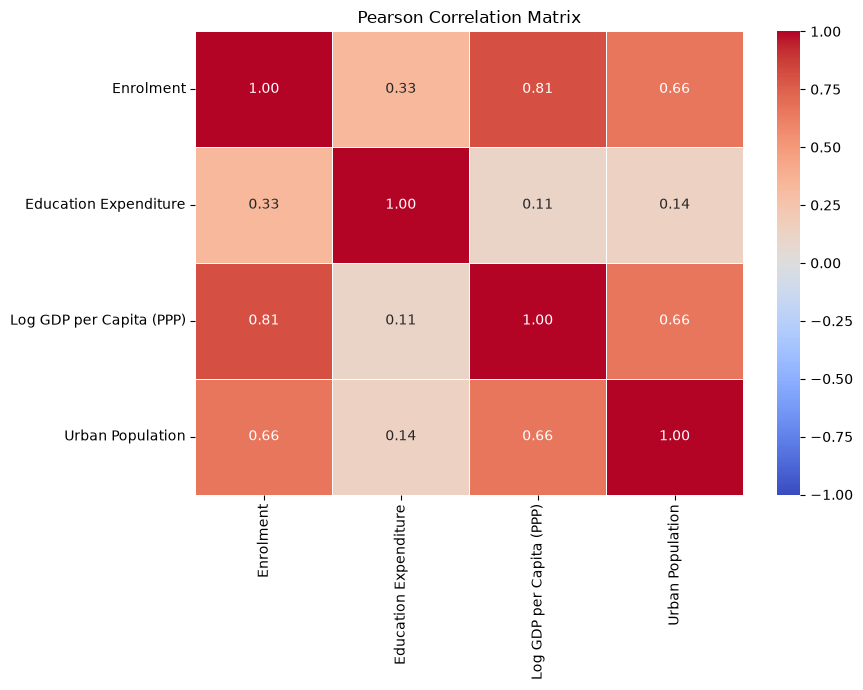

In [42]:
plt.figure(figsize=(9, 7))

sns.heatmap(
    pearson_corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Pearson Correlation Matrix")
plt.tight_layout()
plt.show()
